In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.ensemble import RandomForestClassifier

# 지역적 선형 임베딩(Locally Linear Embedding, LLE)

각 데이터 포인트의 이웃 데이터 중 k개의 이웃 데이터를 선정하고 데이터 자신과 k개의 이웃 데이터를 하나의 덩어리로 가정하고 데이터를 재구성 한다. 기존 데이터 자신의 이웃 데이터를 기준으로 재구성하는 방법으로 해당 데이터 자체보다 주변의 이웃 데이터들이 중요하다.

# 차원을 축소하기 전과 차원을 축소한 후 정확도를 비교한다.

## 와인 데이터를 지역적 선형 임베딩 알고리즘에 사용할 데이터를 준비한다.

In [2]:
raw_data = datasets.load_wine()

xData = raw_data.data
yData = raw_data.target

x_train, x_test, y_train, y_test = train_test_split(xData, yData, random_state=1)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

## 지역적 선형 임베딩 모델을 만들고 학습 시킨다.

지역적 선형 임베딩 알고리즘을 사용하기 위해 LocallyLinearEmbedding를 import 한다.

In [3]:
from sklearn.manifold import LocallyLinearEmbedding

n_components에 축소하려는 차원 크기를 지정해서 지역적 선형 임베딩 모델을 만들고 학습한 후 적용시킨다.

In [4]:
model = LocallyLinearEmbedding(n_components=2)
# 지역적 선형 임베딩도 지도 학습적인 방법이므로 학습 데이터의 피처와 학습 데이터의 피처에 따른 레이블까지 넘겨서 학습시킨다.
# model.fit(x_train, y_train)
# x_train_lle = model.transform(x_train)
x_train_lle = model.fit_transform(x_train, y_train)
x_test_lle = model.transform(x_test)
print(x_train.shape, x_train_lle.shape, x_test.shape, x_test_lle.shape)

(133, 13) (133, 2) (45, 13) (45, 2)


## 임베딩 벡터를 확인한다.

embedding_ 속성으로 차원 축소에 사용된 임베딩 벡터를 얻어올 수 있다.

In [5]:
print(model.embedding_)

[[ 0.10370077  0.03797149]
 [ 0.07222626  0.00764776]
 [ 0.11291288  0.05930921]
 [ 0.11560401  0.06205209]
 [ 0.11854756  0.06719633]
 [-0.02664269 -0.13181186]
 [-0.10501921  0.07537654]
 [-0.10326081  0.07047313]
 [ 0.10811266  0.04689056]
 [-0.04377827 -0.09418701]
 [ 0.0712414   0.01801874]
 [ 0.13033709  0.08810276]
 [ 0.02991311 -0.04069974]
 [-0.07898669  0.01497572]
 [ 0.03473125 -0.05744147]
 [ 0.01943026 -0.04529514]
 [ 0.11959649  0.07007802]
 [-0.10317351  0.07114343]
 [-0.02752016 -0.14962908]
 [-0.1164511   0.10200801]
 [ 0.10508563  0.04186687]
 [-0.01462819 -0.16313682]
 [ 0.06810266 -0.0169578 ]
 [-0.01732533 -0.16242923]
 [ 0.11454199  0.05901053]
 [-0.09625792  0.05485706]
 [-0.11013016  0.08772677]
 [-0.10843424  0.08356562]
 [-0.10619192  0.07755468]
 [-0.08729218  0.04167607]
 [-0.03682447 -0.05761368]
 [ 0.09367018  0.02624216]
 [-0.10295085  0.06762962]
 [ 0.11999055  0.07023365]
 [-0.06361883 -0.0199435 ]
 [-0.11550832  0.09903396]
 [ 0.11279934  0.05534145]
 

## 지역적 선형 임베딩을 통해 차원 축소된 데이터 시각화

In [6]:
df = pd.DataFrame(x_train_lle, columns=['x', 'y'])
df['label'] = y_train
df

,x,y,label
0,0.103701,0.037971,0
1,0.072226,0.007648,1
2,0.112913,0.059309,0
3,0.115604,0.062052,0
4,0.118548,0.067196,0
...,...,...,...
128,-0.122468,0.117589,2
129,-0.106745,0.077409,2
130,0.001631,-0.119052,1
131,-0.111992,0.091476,2


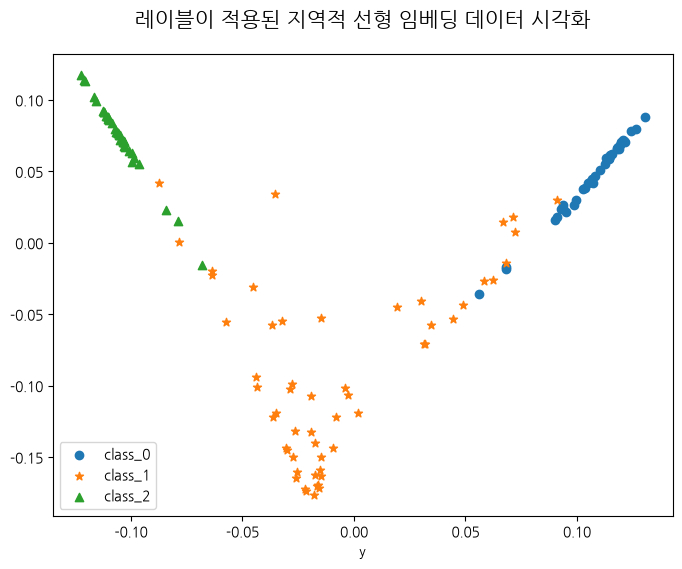

In [7]:
plt.figure(figsize=[8, 6])
markers = ['o', '*', '^', 'v', 's', 'x']

for i in range(len(raw_data.target_names)):
    df_index = df[df.label == i]
    label = raw_data.target_names[i]
    plt.scatter(x=df_index.x, y=df_index.y, label=label, marker=markers[i])

plt.title('레이블이 적용된 지역적 선형 임베딩 데이터 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.xlabel('y')
plt.legend()
plt.show()

## 지역적 선형 임베딩 적용 전, 후 데이터로 랜덤 포레스트 모델로 학습시키고 예측 후 평가한다.

지역적 선형 임베딩 전 데이터 학습 및 예측, 평가

In [8]:
model = RandomForestClassifier(random_state=0, max_depth=2).fit(x_train, y_train)
predict = model.predict(x_test)
print(predict)

[2 1 0 1 0 2 1 0 2 1 0 0 1 0 1 1 2 0 1 0 0 1 2 0 0 2 0 0 0 2 1 2 2 0 1 1 1
 1 1 0 0 1 2 0 0]


In [9]:
classification = classification_report(y_test, predict, target_names=raw_data.target_names)
print(classification)

              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
     class_1       1.00      0.94      0.97        17
     class_2       1.00      1.00      1.00        10

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



지역적 선형 임베딩 후 데이터 학습 및 예측, 평가

In [10]:
model_lle = RandomForestClassifier(random_state=0, max_depth=2).fit(x_train_lle, y_train)
predict_lle = model_lle.predict(x_test_lle)
print(predict_lle)

[2 1 1 1 0 2 1 0 2 1 0 0 1 0 1 1 2 0 1 0 0 1 2 0 0 2 0 0 0 2 1 2 2 0 1 1 1
 1 1 0 0 1 2 1 0]


In [11]:
classification = classification_report(y_test, predict_lle, target_names=raw_data.target_names)
print(classification)

              precision    recall  f1-score   support

     class_0       0.94      0.89      0.91        18
     class_1       0.89      0.94      0.91        17
     class_2       1.00      1.00      1.00        10

    accuracy                           0.93        45
   macro avg       0.94      0.94      0.94        45
weighted avg       0.93      0.93      0.93        45

